# Dehaze, then fuse

Tests whether dehazing the visible frame **before** fusion improves the result. The dehazers come from
`dehazing/methods/` (copied unchanged, only the O-HAZE loading is left out); the fusion models are RFN-Nest with the
published weights and the fine-tuned `rfn_nest_blender_v3`, which are **not retrained**: only their visible input changes.
The thermal input is untouched, so the thermal hot spots cannot be lost by the dehazer itself.

**Why it could help.** RFN-Nest takes from each input where it has more local structure. Fog flattens the visible
frame, so the published model and v3 rely on thermal almost everywhere, although the fog-free frame has detail they
could use (v2 showed it can be recovered, but trained the decoder to do it and lost the hot spots).

**Where it may not.** At night and dusk (clips 01 and 10) the visible frame is nearly black, so a dehazer mostly
stretches noise and quantization; in dense fog there is nothing left to recover. Per-frame dehazers also estimate the
fog (atmospheric light) again on every frame, which can make the video flicker.

| dehazer | from | type |
|---|---|---|
| `dcp` | `dcp.ipynb` | dark channel prior (He et al.), training-free |
| `cap` | `cap.ipynb` | colour attenuation prior (Zhu et al.), training-free |
| `fusion_dehaze` | `fusion_dehaze.ipynb` | multi-scale fusion (Ancuti & Ancuti), training-free |
| `clahe` | `clahe.ipynb` | local contrast equalization, enhancement baseline |
| `retinex` | `retinex.ipynb` | multi-scale Retinex (MSRCP), enhancement baseline |
| `aod_net` | `aod_net.ipynb` | small CNN, public weights or the team's checkpoint; the team's real-time model |

`dip` (about 5 min per image, so days for 990 frames) and `ffa_net` (slow at 1280x720) are left out.

**Two stages.**
1. **Dehazing alone** (cheap, CPU is fine): every `SCORE_STRIDE`-th test frame is dehazed and scored against the
   fog-free frame with SSIM_ref / PSNR_ref, computed exactly as in `FUSION_EVALUATION.ipynb`, next to the hazy input.
   This shows how much each dehazer recovers by itself and how long it takes per frame.
2. **Dehaze + fuse** (needs the T4: one model over the three clips takes about 50 min): the whole test clips are
   fused for the dehazers in `FUSE_DEHAZERS` and the models in `FUSION_MODELS`. Output:
   `out/<model>+<dehazer>_forest_<clip>.mp4`, e.g. `rfn_nest_blender_v3+dcp_forest_07_afternoon_steep-push.mp4`.
   Finished videos are skipped when the notebook runs again (e.g. after a disconnect).

**Inputs**: the sources that `rfn_nest_blender_v1/v2` exported, `data/forest_<clip>/rgb` (hazy visible), `ir`
(registered thermal) and `clear` (fog-free), and the v3 checkpoint `rfn_nest_blender_v3.model`. On Colab both are
already in `DRIVE_OUT`; locally they are `fusion/data/` and `fusion/out/checkpoints/`.

**Scoring**: copy the videos to `fusion/out/` and run `FUSION_EVALUATION.ipynb` per clip. Keep `SOURCE` as is: the
visible source stays the **hazy** frame, so the rows compare directly with `rfn_nest` and `rfn_nest_blender_v3`.
Judge mainly by SSIM_ref / PSNR_ref and by whether the hot spots survive in the snapshot; Q^AB/F, SSIM and Q_CV
compare with the hazy input and so penalize any dehazing.


In [3]:
TEST_CLIPS = ['01_night-moon_nadir-hover', '07_afternoon_steep-push', '10_dusk_high-orbit']

# Colab only: the folder rfn_nest_blender_v1/v2/v3 wrote to (holds data/, checkpoints/ and out/)
DRIVE_OUT = '/content/drive/MyDrive/Vidhance Extended View/models_output/rfn_nest_blender'
OUT_ROOT = None               # None -> DRIVE_OUT on Colab, fusion/ when run locally

# Dehazers
DEHAZERS = ['dcp', 'cap', 'fusion_dehaze', 'clahe', 'retinex', 'aod_net']
AOD_WEIGHTS = 'public'        # 'public' (TheFairBear/PyTorch-Image-Dehazing) or a path to the team's aod_net_best.pth

# Stage 1: dehazing alone
SCORE_STRIDE = 10             # score every n-th frame (~100 frames over the three clips)

# Stage 2: dehaze + fuse
RUN_FUSION = True             # False = stage 1 only
FUSE_DEHAZERS = 'auto'        # 'auto' = the FUSE_TOP_N best of stage 1 (mean SSIM_ref gain over the hazy input),
FUSE_TOP_N = 2                #          or a list such as ['dcp', 'aod_net']
FUSION_MODELS = ['rfn_nest_blender_v3']   # add 'rfn_nest' (published weights) for a second comparison; ~50 min each
NORMALIZE_PER_FRAME = True    # as in rfn_nest_blender_v*, so the rows compare with theirs
MAX_FRAMES = None             # None = whole clip (needed for FUSION_EVALUATION), or an int for a quick look
FPS = 30.0


In [4]:
import os, sys, csv, time, subprocess, zipfile, warnings
from collections import deque
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import numpy as np, cv2, torch
import torch.nn as nn
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount('/content/drive')
    if RUN_FUSION and not torch.cuda.is_available():
        raise RuntimeError('No GPU: choose Runtime > Change runtime type > T4 GPU, or set RUN_FUSION = False.')
    VENDOR = Path('/content/_vendor')
    root = Path(OUT_ROOT or DRIVE_OUT)
    CKPT_DIRS = [root / 'checkpoints']
else:
    here = Path.cwd().resolve()
    fusion = next((d / 'fusion' for d in [here, *here.parents] if (d / 'fusion' / 'data').is_dir()),
                  next((d for d in [here, *here.parents] if d.name == 'fusion' and (d / 'data').is_dir()), None))
    if fusion is None:
        raise FileNotFoundError('Could not find fusion/data from %s. Start Jupyter inside the repo.' % here)
    VENDOR = fusion / 'methods' / '_vendor'
    root = Path(OUT_ROOT) if OUT_ROOT else fusion
    CKPT_DIRS = [root / 'out' / 'checkpoints', root / 'checkpoints']

DATA_DIR, OUT_DIR = root / 'data', root / 'out'
OUT_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'cpu')
print('data:', DATA_DIR, '| outputs:', OUT_DIR)

IMAGE_EXTS = {'.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff'}

def source_dir(clip, stream):
    d = DATA_DIR / ('forest_' + clip) / stream
    if not d.is_dir():
        raise FileNotFoundError('%s not found: run rfn_nest_blender_v2 (EXPORT_EVAL_SOURCES = True) first, '
                                'or copy data/forest_%s from Drive.' % (d, clip))
    return d

FRAMES = {}
for clip in TEST_CLIPS:
    names = {s: sorted(p.name for p in source_dir(clip, s).iterdir() if p.suffix.lower() in IMAGE_EXTS)
             for s in ('rgb', 'ir', 'clear')}
    if not names['rgb'] or names['rgb'] != names['ir'] or names['rgb'] != names['clear']:
        raise ValueError('%s: rgb, ir and clear do not hold the same frames' % clip)
    FRAMES[clip] = names['rgb']
    print('%-28s %d frames' % (clip, len(FRAMES[clip])))

def read(clip, stream, name, flags=cv2.IMREAD_COLOR):
    path = source_dir(clip, stream) / name
    img = cv2.imread(str(path), flags)
    if img is None:
        raise IOError('Could not read %s' % path)
    return img


Mounted at /content/drive
device: Tesla T4
data: /content/drive/MyDrive/Vidhance Extended View/models_output/rfn_nest_blender/data | outputs: /content/drive/MyDrive/Vidhance Extended View/models_output/rfn_nest_blender/out
01_night-moon_nadir-hover    300 frames
07_afternoon_steep-push      270 frames
10_dusk_high-orbit           420 frames


## Dehazers

Each takes and returns a BGR uint8 frame. The code and settings are those of the notebooks in `dehazing/methods/`;
only the input/output conversions are adapted (DCP and AOD-Net work in RGB there).


In [5]:
def guided_filter(guide, src, r, eps):
    """Edge-preserving smoothing of `src`, following the edges of `guide` (He et al., 2010)."""
    box = lambda x: cv2.boxFilter(x, -1, (2 * r + 1, 2 * r + 1))
    mean_I, mean_p = box(guide), box(src)
    a = (box(guide * src) - mean_I * mean_p) / (box(guide * guide) - mean_I * mean_I + eps)
    b = mean_p - a * mean_I
    return box(a) * guide + box(b)


# ---- DCP (dcp.ipynb) ------------------------------------------------------------------------------------------
DCP = dict(PATCH=15, OMEGA=0.95, TOP_PERCENT=0.001, T0=0.1, GF_RADIUS=60, GF_EPS=1e-4)

def dark_channel(img, patch=DCP['PATCH']):
    return cv2.erode(img.min(axis=2), cv2.getStructuringElement(cv2.MORPH_RECT, (patch, patch)))

def dehaze_dcp(bgr):
    img = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB).astype(np.float32) / 255
    dark = dark_channel(img)
    n = max(int(dark.size * DCP['TOP_PERCENT']), 1)
    cand = np.argpartition(dark.ravel(), -n)[-n:]
    flat = img.reshape(-1, 3)
    A = flat[cand[flat[cand].sum(axis=1).argmax()]]
    t = 1 - DCP['OMEGA'] * dark_channel(img / A)
    t = guided_filter(cv2.cvtColor(img, cv2.COLOR_RGB2GRAY), t.astype(np.float32), DCP['GF_RADIUS'], DCP['GF_EPS'])
    J = (img - A) / np.maximum(t, DCP['T0'])[..., None] + A
    return cv2.cvtColor((np.clip(J, 0, 1) * 255 + 0.5).astype(np.uint8), cv2.COLOR_RGB2BGR)


# ---- CAP (cap.ipynb) ------------------------------------------------------------------------------------------
CAP = dict(T0=0.121779, T1=0.959710, T2=-0.780245, BETA=1.0, PATCH=15, TOP_PERCENT=0.001,
           T_MIN=0.1, T_MAX=0.9, GF_RADIUS=60, GF_EPS=1e-3)

def dehaze_cap(bgr):
    I = bgr.astype(np.float32) / 255
    hsv = cv2.cvtColor(I, cv2.COLOR_BGR2HSV)
    d = CAP['T0'] + CAP['T1'] * hsv[..., 2] + CAP['T2'] * hsv[..., 1]
    d = cv2.erode(d, cv2.getStructuringElement(cv2.MORPH_RECT, (CAP['PATCH'], CAP['PATCH'])))
    d = guided_filter(cv2.cvtColor(I, cv2.COLOR_BGR2GRAY), d.astype(np.float32), CAP['GF_RADIUS'], CAP['GF_EPS'])
    n = max(int(d.size * CAP['TOP_PERCENT']), 1)
    cand = np.argpartition(d.ravel(), -n)[-n:]
    flat = I.reshape(-1, 3)
    A = flat[cand[flat[cand].sum(axis=1).argmax()]]
    t = np.clip(np.exp(-CAP['BETA'] * d), CAP['T_MIN'], CAP['T_MAX'])
    J = (I - A) / t[..., None] + A
    return (np.clip(J, 0, 1) * 255 + 0.5).astype(np.uint8)


# ---- multi-scale fusion (fusion_dehaze.ipynb) -----------------------------------------------------------------
FD = dict(GAMMA=2.5, LEVELS=5, EXP_SIGMA=0.25)

def gaussian_pyr(img, levels=FD['LEVELS']):
    pyr = [img]
    for _ in range(levels - 1):
        pyr.append(cv2.pyrDown(pyr[-1]))
    return pyr

def laplacian_pyr(img, levels=FD['LEVELS']):
    g = gaussian_pyr(img, levels)
    return [g[i] - cv2.pyrUp(g[i + 1], dstsize=g[i].shape[1::-1]) for i in range(levels - 1)] + [g[-1]]

def fd_weights(img):
    L = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)[..., 0] / 100.0
    contrast = np.abs(cv2.Laplacian(L, cv2.CV_32F))
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    saliency = np.linalg.norm(cv2.GaussianBlur(lab, (5, 5), 0) - lab.reshape(-1, 3).mean(0), axis=2)
    saliency /= saliency.max() + 1e-8
    exposed = np.exp(-((L - 0.5) ** 2) / (2 * FD['EXP_SIGMA'] ** 2))
    return contrast + saliency + exposed

def dehaze_fusion(bgr):
    I = bgr.astype(np.float32) / 255
    I1 = np.clip(I * (I.mean() / (I.reshape(-1, 3).mean(0) + 1e-8)), 0, 1)
    mean_lum = cv2.cvtColor(I, cv2.COLOR_BGR2GRAY).mean()
    I2 = np.clip(FD['GAMMA'] * (I - mean_lum) + mean_lum, 0, 1)
    W1, W2 = fd_weights(I1), fd_weights(I2)
    W1, W2 = W1 / (W1 + W2 + 1e-8), W2 / (W1 + W2 + 1e-8)
    fused = [w1[..., None] * l1 + w2[..., None] * l2
             for l1, l2, w1, w2 in zip(laplacian_pyr(I1), laplacian_pyr(I2), gaussian_pyr(W1), gaussian_pyr(W2))]
    out = fused[-1]
    for lev in reversed(fused[:-1]):
        out = cv2.pyrUp(out, dstsize=lev.shape[1::-1]) + lev
    return (np.clip(out, 0, 1) * 255 + 0.5).astype(np.uint8)


# ---- CLAHE (clahe.ipynb) --------------------------------------------------------------------------------------
def dehaze_clahe(bgr, clip_limit=2.0, tile_grid=(8, 8)):
    l, a, b = cv2.split(cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB))
    l = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid).apply(l)
    return cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2BGR)


# ---- Retinex MSRCP (retinex.ipynb) ----------------------------------------------------------------------------
RETINEX = dict(SIGMAS=(15, 80, 250), LOW=1.0, HIGH=99.0)

def dehaze_retinex(bgr):
    f = bgr.astype(np.float64) + 1.0
    intensity = f.mean(axis=2)
    msr = sum(np.log(intensity) - np.log(cv2.GaussianBlur(intensity, (0, 0), s)) for s in RETINEX['SIGMAS'])
    msr /= len(RETINEX['SIGMAS'])
    lo, hi = np.percentile(msr, RETINEX['LOW']), np.percentile(msr, RETINEX['HIGH'])
    int1 = np.clip((msr - lo) / (hi - lo + 1e-8), 0, 1) * 254 + 1
    ratio = np.minimum(int1 / intensity, 255.0 / f.max(axis=2))
    return np.clip(f * ratio[..., None], 0, 255).astype(np.uint8)


# ---- AOD-Net (aod_net.ipynb) ----------------------------------------------------------------------------------
class AODNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.relu = nn.ReLU(inplace=True)
        self.conv1 = nn.Conv2d(3, 3, kernel_size=1, padding=0)
        self.conv2 = nn.Conv2d(3, 3, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(6, 3, kernel_size=5, padding=2)
        self.conv4 = nn.Conv2d(6, 3, kernel_size=7, padding=3)
        self.conv5 = nn.Conv2d(12, 3, kernel_size=3, padding=1)
        self.b = 1.0

    def forward(self, x):
        x1 = self.relu(self.conv1(x))
        x2 = self.relu(self.conv2(x1))
        x3 = self.relu(self.conv3(torch.cat([x1, x2], dim=1)))
        x4 = self.relu(self.conv4(torch.cat([x2, x3], dim=1)))
        k = self.relu(self.conv5(torch.cat([x1, x2, x3, x4], dim=1)))
        return torch.clamp(self.relu(k * x - k + self.b), 0, 1)

aod = None
if 'aod_net' in DEHAZERS:
    if AOD_WEIGHTS == 'public':
        repo = VENDOR / 'PyTorch-Image-Dehazing'
        if not repo.is_dir():
            VENDOR.mkdir(parents=True, exist_ok=True)
            subprocess.run(['git', 'clone', '-q', '--depth', '1',
                            'https://github.com/TheFairBear/PyTorch-Image-Dehazing.git', str(repo)], check=True)
        aod_ckpt = repo / 'snapshots' / 'dehazer.pth'
    else:
        aod_ckpt = Path(AOD_WEIGHTS)
    state = torch.load(aod_ckpt, map_location='cpu')
    aod = AODNet()
    aod.load_state_dict({k.replace('e_conv', 'conv'): v for k, v in state.items()}, strict=True)
    aod = aod.to(DEVICE).eval()
    print('AOD-Net weights:', aod_ckpt)

@torch.no_grad()
def dehaze_aod(bgr):
    x = torch.from_numpy(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB).astype(np.float32) / 255).permute(2, 0, 1)[None]
    y = aod(x.to(DEVICE))[0].permute(1, 2, 0).cpu().numpy()
    return cv2.cvtColor((y * 255 + 0.5).astype(np.uint8), cv2.COLOR_RGB2BGR)


ALL_DEHAZERS = dict(dcp=dehaze_dcp, cap=dehaze_cap, fusion_dehaze=dehaze_fusion, clahe=dehaze_clahe,
                    retinex=dehaze_retinex, aod_net=dehaze_aod)
unknown = set(DEHAZERS) - set(ALL_DEHAZERS)
if unknown:
    raise ValueError('Unknown dehazer(s): %s' % sorted(unknown))
DEHAZE = {name: ALL_DEHAZERS[name] for name in DEHAZERS}


AOD-Net weights: /content/_vendor/PyTorch-Image-Dehazing/snapshots/dehazer.pth


## Stage 1: dehazing alone

SSIM_ref and PSNR_ref as in `FUSION_EVALUATION.ipynb`: grey images, the frame is first matched to the fog-free frame
with one gain and offset (so brightness does not count), then compared. `hazy` is the untouched input: a dehazer
that does not beat it recovers nothing measurable. `ms/frame` is the CPU or GPU time of the dehazer alone.


In [6]:
def to_gray(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float64)

def ssim(x, y, data_range=255.0):
    C1, C2 = (0.01 * data_range) ** 2, (0.03 * data_range) ** 2
    blur = lambda z: cv2.GaussianBlur(z, (11, 11), 1.5)
    mx, my = blur(x), blur(y)
    vx, vy = blur(x * x) - mx ** 2, blur(y * y) - my ** 2
    cxy = blur(x * y) - mx * my
    m = ((2 * mx * my + C1) * (2 * cxy + C2)) / ((mx ** 2 + my ** 2 + C1) * (vx + vy + C2))
    return float(m[5:-5, 5:-5].mean())

def reference_metrics(r, x):
    """SSIM and PSNR of grey image x against the grey reference r, after a global gain + offset match (gain >= 0)."""
    gain = max(((x - x.mean()) * (r - r.mean())).mean() / max(x.var(), 1e-12), 0.0)
    matched = np.clip(gain * (x - x.mean()) + r.mean(), 0, 255)
    mse = ((matched - r) ** 2).mean()
    return ssim(r, matched), 10 * np.log10(255.0 ** 2 / mse) if mse > 0 else np.inf

scores = {}            # (clip, dehazer) -> list of (ssim_ref, psnr_ref)
timings = {name: [] for name in DEHAZE}
examples = {}          # (clip, dehazer) -> middle scored frame
for clip in TEST_CLIPS:
    names = FRAMES[clip][:MAX_FRAMES][::SCORE_STRIDE]
    for i, name in enumerate(tqdm(names, desc=clip, leave=False)):
        hazy, ref = read(clip, 'rgb', name), to_gray(read(clip, 'clear', name))
        outputs = {'hazy': hazy}
        for dname, fn in DEHAZE.items():
            t0 = time.perf_counter()
            outputs[dname] = fn(hazy)
            timings[dname].append(time.perf_counter() - t0)
        for dname, img in outputs.items():
            scores.setdefault((clip, dname), []).append(reference_metrics(ref, to_gray(img)))
        if i == len(names) // 2:
            examples.update({(clip, d): img for d, img in outputs.items()})
            examples[clip, 'clear'] = read(clip, 'clear', name)

rows = []
for (clip, dname), vals in scores.items():
    s, p = np.mean(vals, axis=0)
    rows.append(dict(clip=clip, dehazer=dname, SSIM_ref=s, PSNR_ref=p))
base = {r['clip']: r for r in rows if r['dehazer'] == 'hazy'}
for r in rows:
    r['SSIM_gain'] = r['SSIM_ref'] - base[r['clip']]['SSIM_ref']
    r['PSNR_gain'] = r['PSNR_ref'] - base[r['clip']]['PSNR_ref']

with open(OUT_DIR / 'dehaze_only_scores.csv', 'w', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=list(rows[0]))
    writer.writeheader()
    writer.writerows(rows)

print('%-28s %-14s %9s %9s %10s %10s' % ('clip', 'dehazer', 'SSIM_ref', 'PSNR_ref', 'SSIM gain', 'PSNR gain'))
for r in rows:
    print('%-28s %-14s %9.3f %9.2f %+10.3f %+10.2f' % (r['clip'], r['dehazer'], r['SSIM_ref'], r['PSNR_ref'],
                                                     r['SSIM_gain'], r['PSNR_gain']))
mean_gain = {d: np.mean([r['SSIM_gain'] for r in rows if r['dehazer'] == d]) for d in DEHAZE}
print('\n%-14s %16s %10s' % ('dehazer', 'mean SSIM gain', 'ms/frame'))
for d in sorted(mean_gain, key=mean_gain.get, reverse=True):
    print('%-14s %+16.3f %10.0f' % (d, mean_gain[d], 1000 * np.median(timings[d])))
print('saved', OUT_DIR / 'dehaze_only_scores.csv')


01_night-moon_nadir-hover:   0%|          | 0/30 [00:00<?, ?it/s]

07_afternoon_steep-push:   0%|          | 0/27 [00:00<?, ?it/s]

10_dusk_high-orbit:   0%|          | 0/42 [00:00<?, ?it/s]

clip                         dehazer         SSIM_ref  PSNR_ref  SSIM gain  PSNR gain
01_night-moon_nadir-hover    hazy               0.801     27.86     +0.000      +0.00
01_night-moon_nadir-hover    dcp                0.798     28.09     -0.003      +0.23
01_night-moon_nadir-hover    cap                0.800     27.86     -0.001      -0.01
01_night-moon_nadir-hover    fusion_dehaze      0.804     27.90     +0.002      +0.04
01_night-moon_nadir-hover    clahe              0.795     28.58     -0.007      +0.71
01_night-moon_nadir-hover    retinex            0.781     28.09     -0.021      +0.23
01_night-moon_nadir-hover    aod_net            0.711     24.94     -0.090      -2.92
07_afternoon_steep-push      hazy               0.495     17.43     +0.000      +0.00
07_afternoon_steep-push      dcp                0.547     19.30     +0.051      +1.87
07_afternoon_steep-push      cap                0.514     17.79     +0.019      +0.36
07_afternoon_steep-push      fusion_dehaze      0.497 

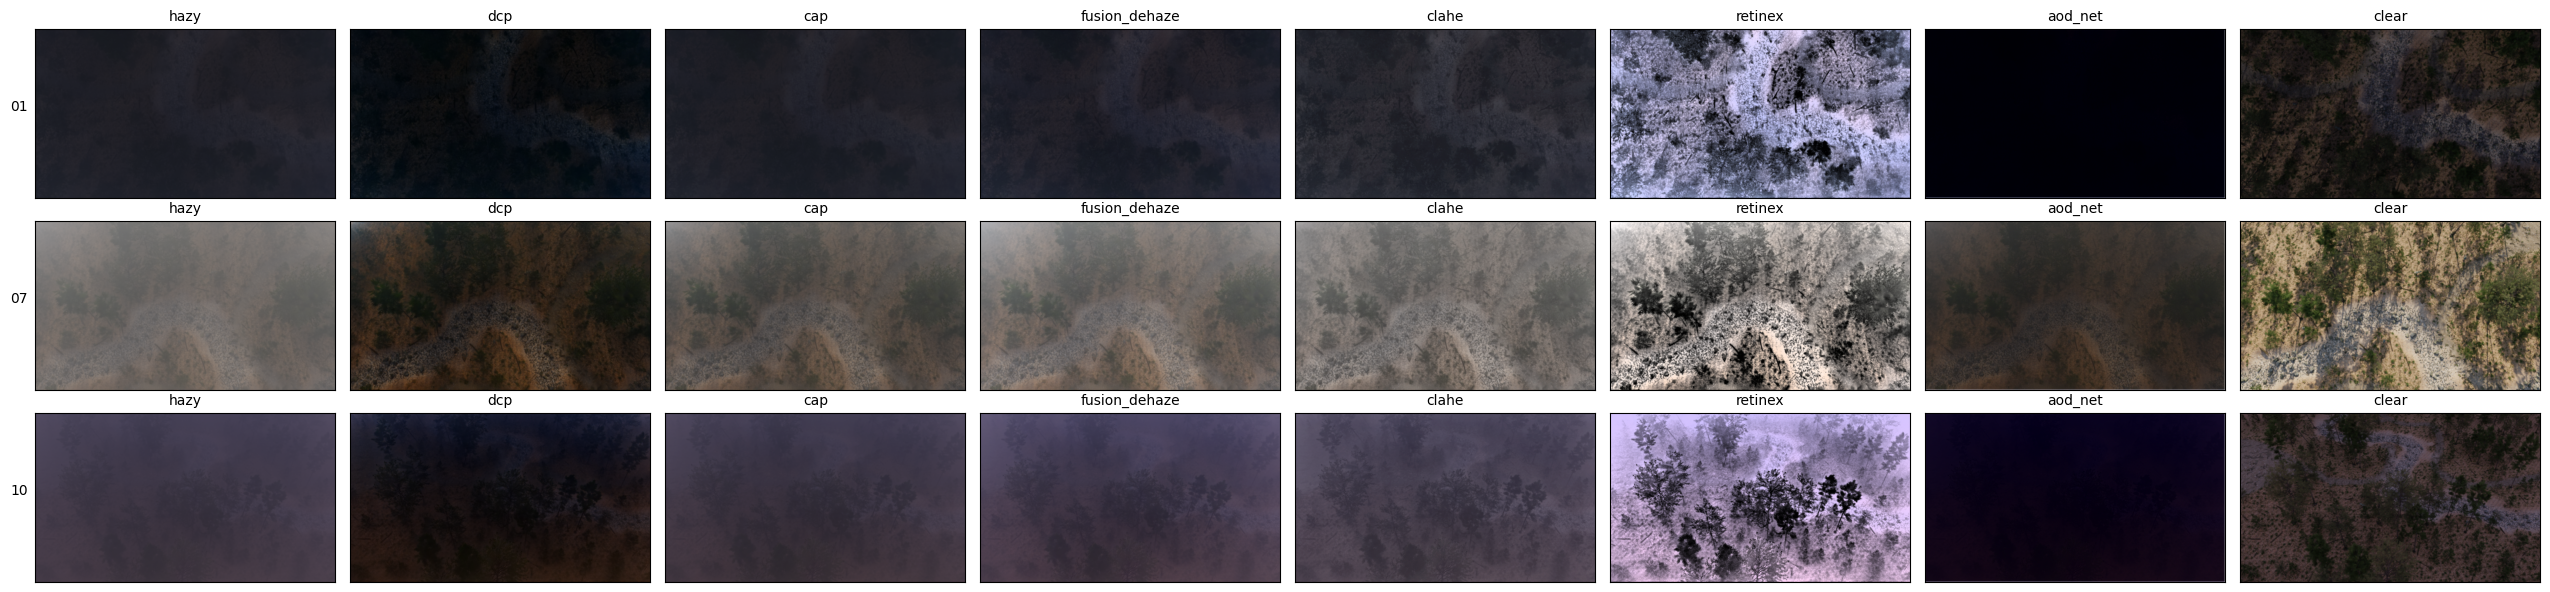

In [7]:
# Middle scored frame of each clip: hazy input, every dehazer, fog-free frame
columns = ['hazy', *DEHAZE, 'clear']
fig, axes = plt.subplots(len(TEST_CLIPS), len(columns), figsize=(3.2 * len(columns), 2.0 * len(TEST_CLIPS)),
                         squeeze=False)
for row_axes, clip in zip(axes, TEST_CLIPS):
    for ax, col in zip(row_axes, columns):
        ax.imshow(cv2.cvtColor(examples[clip, col], cv2.COLOR_BGR2RGB))
        ax.set_title(col, fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])
    row_axes[0].set_ylabel(clip[:2], rotation=0, labelpad=12)
fig.tight_layout()
plt.show()


## Stage 2: dehaze + fuse

The dehazed frame is converted to grey and replaces the hazy visible input of the fusion model; the thermal input and
the model are unchanged. Dehazing runs on CPU threads while the GPU fuses. Each video is written under a temporary
name and renamed only when complete, so a disconnect never leaves a truncated video that looks finished.


In [8]:
if not RUN_FUSION:
    print('RUN_FUSION = False: stage 2 skipped.')
else:
    REPO_DIR = VENDOR / 'imagefusion-rfn-nest'
    if not REPO_DIR.is_dir():
        VENDOR.mkdir(parents=True, exist_ok=True)
        subprocess.run(['git', 'clone', '--depth', '1',
                        'https://github.com/hli1221/imagefusion-rfn-nest.git', str(REPO_DIR)], check=True)
    MODELS = REPO_DIR / 'models'
    for stem in ('nestfuse', 'rfn_twostage'):
        if not (MODELS / stem).is_dir():
            with zipfile.ZipFile(MODELS / (stem + '.zip')) as zf:
                zf.extractall(MODELS)
    sys.path.insert(0, str(REPO_DIR))
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        from net import NestFuse_light2_nodense, Fusion_network

    NB_FILTER = [64, 112, 160, 208, 256]
    NEST_CKPT = MODELS / 'nestfuse' / 'nestfuse_gray_1e2.model'
    PUBLISHED_RFN_CKPT = MODELS / 'rfn_twostage' / '6.0' / 'Final_epoch_2_alpha_700_wir_6.0_wvi_3.0_ssim_vi.model'

    def checkpoint(model):
        if model == 'rfn_nest':
            return PUBLISHED_RFN_CKPT
        for d in CKPT_DIRS:
            if (d / (model + '.model')).exists():
                return d / (model + '.model')
        raise FileNotFoundError('%s.model not found in %s. Copy it from Drive (models_output/rfn_nest_blender/'
                                'checkpoints) or remove %r from FUSION_MODELS.' % (model, [str(d) for d in CKPT_DIRS], model))

    def load_models(path):
        """(NestFuse, RFN): the {'rfn', 'nest'} format of rfn_nest_blender_v2/v3, or an RFN-only checkpoint."""
        state = torch.load(path, map_location='cpu')
        nest = NestFuse_light2_nodense(NB_FILTER, 1, 1, deepsupervision=False)
        nest.load_state_dict(state['nest'] if 'rfn' in state else torch.load(NEST_CKPT, map_location='cpu'))
        rfn = Fusion_network(NB_FILTER, 'res')
        rfn.load_state_dict(state['rfn'] if 'rfn' in state else state)
        return nest.eval().to(DEVICE), rfn.eval().to(DEVICE)

    def to_batch(img):
        return torch.from_numpy(img).float()[None, None].to(DEVICE)

    @torch.no_grad()
    def fuse_frame(nest, rfn, ir, vi):
        out = nest.decoder_eval(rfn(nest.encoder(to_batch(ir)), nest.encoder(to_batch(vi))))[0][0, 0].float().cpu().numpy()
        if NORMALIZE_PER_FRAME:
            out = (out - out.min()) / (out.max() - out.min() + 1e-5) * 255
        return np.clip(out, 0, 255).astype(np.uint8)

    def make_writer(path, size):
        for codec in ('avc1', 'mp4v'):
            writer = cv2.VideoWriter(str(path), cv2.VideoWriter_fourcc(*codec), FPS, size)
            if writer.isOpened():
                return writer
        raise RuntimeError('OpenCV could not open a video writer for %s' % path)

    def inputs(clip, names, dehaze, pool, ahead=8):
        """(thermal, dehazed grey visible) per frame, prepared `ahead` frames in advance on CPU threads."""
        job = lambda n: (read(clip, 'ir', n, cv2.IMREAD_GRAYSCALE),
                         cv2.cvtColor(dehaze(read(clip, 'rgb', n)), cv2.COLOR_BGR2GRAY))
        queue = deque()
        for n in names:
            queue.append(pool.submit(job, n))
            if len(queue) > ahead:
                yield queue.popleft().result()
        while queue:
            yield queue.popleft().result()

    if FUSE_DEHAZERS == 'auto':
        fuse_dehazers = sorted(mean_gain, key=mean_gain.get, reverse=True)[:FUSE_TOP_N]
        print('best %d of stage 1:' % FUSE_TOP_N, fuse_dehazers)
    else:
        fuse_dehazers = list(FUSE_DEHAZERS)
        missing = set(fuse_dehazers) - set(DEHAZE)
        if missing:
            raise ValueError('FUSE_DEHAZERS not in DEHAZERS: %s' % sorted(missing))

    cv2.setNumThreads(1)
    pool = ThreadPoolExecutor(4 if 'aod_net' not in fuse_dehazers or DEVICE == 'cpu' else 2)
    fused_examples = {}
    for model in FUSION_MODELS:
        nest, rfn = load_models(checkpoint(model))
        print('model %s (%s)' % (model, checkpoint(model).name))
        for dname in fuse_dehazers:
            method = '%s+%s' % (model, dname)
            for clip in TEST_CLIPS:
                names = FRAMES[clip][:MAX_FRAMES]
                out_path = OUT_DIR / ('%s_forest_%s.mp4' % (method, clip))
                if out_path.exists() and MAX_FRAMES is None:
                    print('  exists, skipped:', out_path.name)
                    continue
                tmp_path = OUT_DIR / ('.%s_forest_%s.partial.mp4' % (method, clip))
                h, w = read(clip, 'ir', names[0], cv2.IMREAD_GRAYSCALE).shape
                writer, t0 = make_writer(tmp_path, (w, h)), time.time()
                try:
                    for i, (ir, vi) in enumerate(tqdm(inputs(clip, names, DEHAZE[dname], pool), total=len(names),
                                                      desc='%s %s' % (method, clip[:2]), leave=False)):
                        fused = fuse_frame(nest, rfn, ir, vi)
                        writer.write(cv2.cvtColor(fused, cv2.COLOR_GRAY2BGR))
                        if i == len(names) // 2:
                            fused_examples[clip, method] = (vi, fused)
                finally:
                    writer.release()
                os.replace(tmp_path, out_path)
                sec = time.time() - t0
                print('  %d frames in %.0f s (%.1f fps) -> %s' % (len(names), sec, len(names) / sec, out_path.name))
        del nest, rfn
        if DEVICE == 'cuda':
            torch.cuda.empty_cache()
    pool.shutdown()


best 2 of stage 1: ['clahe', 'dcp']
model rfn_nest_blender_v3 (rfn_nest_blender_v3.model)


rfn_nest_blender_v3+clahe 01:   0%|          | 0/300 [00:00<?, ?it/s]

  300 frames in 282 s (1.1 fps) -> rfn_nest_blender_v3+clahe_forest_01_night-moon_nadir-hover.mp4


rfn_nest_blender_v3+clahe 07:   0%|          | 0/270 [00:00<?, ?it/s]

  270 frames in 254 s (1.1 fps) -> rfn_nest_blender_v3+clahe_forest_07_afternoon_steep-push.mp4


rfn_nest_blender_v3+clahe 10:   0%|          | 0/420 [00:00<?, ?it/s]

... (3 outputs left out)

rfn_nest_blender_v3+dcp 07:   0%|          | 0/270 [00:00<?, ?it/s]

  270 frames in 254 s (1.1 fps) -> rfn_nest_blender_v3+dcp_forest_07_afternoon_steep-push.mp4


rfn_nest_blender_v3+dcp 10:   0%|          | 0/420 [00:00<?, ?it/s]

  420 frames in 394 s (1.1 fps) -> rfn_nest_blender_v3+dcp_forest_10_dusk_high-orbit.mp4


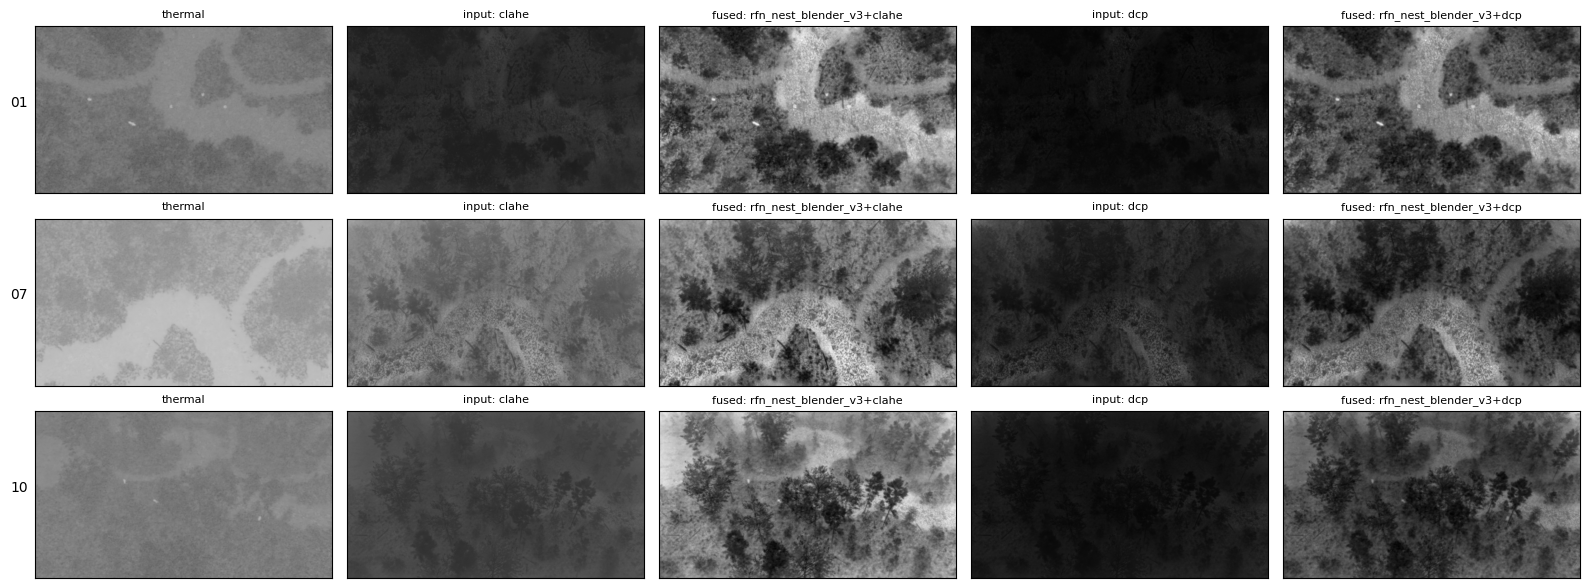

Videos are in /content/drive/MyDrive/Vidhance Extended View/models_output/rfn_nest_blender/out
Score them with FUSION_EVALUATION.ipynb, SOURCE = ['forest_01_night-moon_nadir-hover', 'forest_07_afternoon_steep-push', 'forest_10_dusk_high-orbit']


In [9]:
# Middle frame of each clip: thermal, then per method the dehazed grey input and the fused output
if RUN_FUSION and fused_examples:
    methods = sorted({m for _, m in fused_examples})
    clips = [c for c in TEST_CLIPS if any((c, m) in fused_examples for m in methods)]
    ncol = 1 + 2 * len(methods)
    fig, axes = plt.subplots(len(clips), ncol, figsize=(3.2 * ncol, 2.0 * len(clips)), squeeze=False)
    for row_axes, clip in zip(axes, clips):
        names = FRAMES[clip][:MAX_FRAMES]
        panels = [('thermal', read(clip, 'ir', names[len(names) // 2], cv2.IMREAD_GRAYSCALE))]
        for m in methods:
            vi, fused = fused_examples.get((clip, m), (None, None))
            panels += [('input: ' + m.split('+')[1], vi), ('fused: ' + m, fused)]
        for ax, (title, img) in zip(row_axes, panels):
            if img is not None:
                ax.imshow(img, cmap='gray', vmin=0, vmax=255)
            ax.set_title(title, fontsize=8)
            ax.set_xticks([]); ax.set_yticks([])
        row_axes[0].set_ylabel(clip[:2], rotation=0, labelpad=12)
    fig.tight_layout()
    plt.show()
print('Videos are in', OUT_DIR)
print('Score them with FUSION_EVALUATION.ipynb, SOURCE =', ['forest_' + c for c in TEST_CLIPS])
